# Project Magnolia — Sell-Side Valuation Working Notes

**Engagement:** CenterCap Group (illustrative) has been retained as exclusive sell-side
financial advisor to **Magnolia Multifamily Partners, LLC**, a privately held multifamily
operating company with a 12-property, ~3,000-unit garden-style/mid-rise portfolio
concentrated in the Atlanta, GA metro area. We are exploring a full sale or majority
recapitalization on behalf of the Company's ownership group.

These are my working notes for the valuation workstream: the asset-level model, the
DCF, the comps and precedent transactions cross-checks, the football field, and the
buyer screen. Everything below runs on the `real_estate_ma_toolkit` package in this repo.

> **Illustrative data.** The company, portfolio, comps, and precedent transaction data
> used throughout are synthetic/illustrative, built to be realistic in magnitude and
> convention. This notebook is a methodology demonstration, not a live deal analysis —
> see the project README for the full disclaimer.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from real_estate_ma_toolkit import scenario, comps_analysis, precedent_transactions, buyer_screening
from real_estate_ma_toolkit.dcf_valuation import (
    run_dcf,
    unlevered_free_cash_flow,
    sensitivity_table_gordon_growth,
    sensitivity_table_exit_cap_rate,
)
from real_estate_ma_toolkit.valuation_summary import (
    MethodologyRange,
    build_summary_table,
    overall_recommended_range,
    plot_football_field,
)

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
%matplotlib inline

## 1. The Portfolio

Twelve garden-style/mid-rise assets, built 2006–2019, all in Atlanta-metro submarkets.
Before building anything company-level, I want to see the asset-level detail the same
way I'd review it in an offering memorandum: unit count, Year 1 NOI, going-in cap rate,
and current leverage per property.

In [2]:
company = scenario.load_portfolio_company()

print(f"{company.name}")
print(f"Properties: {len(company.properties)}    Total units: {company.total_units():,}")
print(f"Weighted average going-in cap rate: {company.weighted_avg_going_in_cap_rate():.2%}")
print(f"Portfolio as-is direct-cap value: ${company.portfolio_direct_cap_value():,.0f}")
print(f"Consolidated net debt: ${company.net_debt():,.0f}")

company.property_summary()

Magnolia Multifamily Partners, LLC
Properties: 12    Total units: 3,060
Weighted average going-in cap rate: 4.92%
Portfolio as-is direct-cap value: $606,196,746
Consolidated net debt: $315,000,000


,name,submarket,units,year_built,year1_noi,going_in_cap_rate,direct_cap_value,debt_balance,loan_to_value
property_id,,,,,,,,,
P01,The Ashford at Buckhead,Buckhead,220,2016,"2,534,188.00",0.05,"55,091,043.48",26500000,0.48
P02,Midtown Skyline Flats,Midtown,330,2018,"4,195,902.00",0.04,"93,242,266.67",42000000,0.45
P03,Sandy Springs Reserve,Sandy Springs,280,2012,"2,651,771.20",0.05,"53,035,424.00",28500000,0.54
P04,Alpharetta Commons,Alpharetta,290,2014,"2,706,553.80",0.05,"53,069,682.35",27500000,0.52
P05,Decatur Junction,Decatur,180,2009,"1,432,773.60",0.05,"27,033,464.15",16000000,0.59
P06,Marietta Trails,Marietta,280,2007,"2,058,696.00",0.06,"36,762,428.57",22000000,0.60
P07,Smyrna Vinings Park,Smyrna,300,2015,"3,280,288.00",0.05,"68,339,333.33",32000000,0.47
P08,Perimeter Center Lofts,Sandy Springs / Perimeter,250,2017,"2,904,900.00",0.05,"61,806,382.98",28000000,0.45
P09,East Point Commons,East Point,200,2006,"1,211,880.00",0.06,"20,198,000.00",12500000,0.62


A few things stand out from the asset-level table that will matter later in the buyer
screen: East Point Commons, Marietta Trails, and Kennesaw Ridge are running below the
portfolio's 93% occupancy target and trade at wider cap rates — these are the assets
with the most embedded lease-up upside, and they're exactly the kind of story a
value-add buyer (rather than a core/core-plus buyer) would underwrite most aggressively.

## 2. Company-Level Financial Model

Rolling the twelve property-level models up to a consolidated, 5-year company
projection. A few real-estate-specific modeling choices worth flagging:

- **NOI, not EBIT**, is the unit of analysis at the property level — revenue (rent net
  of vacancy, plus ancillary income) less operating expenses, with property tax and
  insurance grown at their *own* rates rather than lumped into a single opex line.
  Insurance is grown at 6.0%/year here, well above general expense inflation, reflecting
  the real, well-documented run-up in Sun Belt multifamily insurance costs.
- **FFO and AFFO** are computed the standard REIT way (see README for the full
  definition): FFO = NOI after corporate G&A, less cash interest expense; AFFO = FFO
  less recurring CapEx reserves. This is what the comps analysis will apply public
  P/FFO and P/AFFO multiples against — not net income or EPS.
- I project one extra year (Year 6) beyond the 5-year explicit period purely to get a
  **forward NOI** figure for the exit-cap-rate terminal value in the DCF below.

In [3]:
projection = company.project(scenario.GROWTH_ASSUMPTIONS, years=scenario.PROJECTION_YEARS + 1)
explicit_period = projection.loc[1:scenario.PROJECTION_YEARS]

display_cols = ["noi", "corporate_ga", "company_noi_after_ga", "total_interest_expense",
                 "company_ffo", "capex_reserve", "company_affo"]
projection[display_cols].rename(columns={
    "noi": "Portfolio NOI",
    "corporate_ga": "Corporate G&A",
    "company_noi_after_ga": "NOI after G&A (EBITDA proxy)",
    "total_interest_expense": "Interest Expense",
    "company_ffo": "FFO",
    "capex_reserve": "CapEx Reserves",
    "company_affo": "AFFO",
})

,Portfolio NOI,Corporate G&A,NOI after G&A (EBITDA proxy),Interest Expense,FFO,CapEx Reserves,AFFO
year,,,,,,,
1,"30,904,818.89","3,587,500.00","27,317,318.89","16,164,799.26","11,152,519.63",918000,"10,234,519.63"
2,"32,013,849.34","3,677,187.50","28,336,661.84","16,042,410.62","12,294,251.22",918000,"11,376,251.22"
3,"32,839,475.50","3,769,117.19","29,070,358.31","15,879,207.14","13,191,151.17",918000,"12,273,151.17"
4,"33,683,376.89","3,863,345.12","29,820,031.77","15,654,048.00","14,165,983.77",918000,"13,247,983.77"
5,"34,545,761.38","3,959,928.75","30,585,832.63","15,382,904.97","15,202,927.67",918000,"14,284,927.67"
6,"35,426,824.20","4,058,926.96","31,367,897.24","15,097,926.62","16,269,970.62",918000,"15,351,970.62"


## 3. DCF Valuation

Real estate DCFs run on **unlevered free cash flow built from NOI**, not EBIT with a
D&A add-back — there's no separate D&A adjustment because NOI already excludes debt
service, and Magnolia (like most real estate operating vehicles) is structured to avoid
entity-level income tax, so unlevered FCF here is simply NOI after corporate G&A, less
recurring CapEx reserves.

The discount rate is a standard CAPM-based WACC. The terminal value is run **two ways**:

1. **Gordon Growth** — the standard perpetuity growth method.
2. **Exit cap rate** — the real-estate-native method: apply an assumed cap rate to
   forward (Year 6) NOI to get a terminal enterprise value, the same way a buyer at
   exit would actually underwrite the asset. This is a materially more defensible
   "exit multiple" for a real estate business than a generic EV/EBITDA exit multiple.

In [4]:
wacc_inputs = scenario.WACC_INPUTS
print(f"Cost of equity (CAPM): {wacc_inputs.cost_of_equity():.2%}")
print(f"After-tax cost of debt: {wacc_inputs.after_tax_cost_of_debt():.2%}")
print(f"WACC: {wacc_inputs.wacc():.2%}")

exit_cap_rate = scenario.default_exit_cap_rate(company)
print(f"\nAssumed exit cap rate (going-in {company.weighted_avg_going_in_cap_rate():.2%} + "
      f"{scenario.EXIT_CAP_RATE_PREMIUM:.2%} premium): {exit_cap_rate:.2%}")

Cost of equity (CAPM): 10.30%
After-tax cost of debt: 5.75%
WACC: 7.80%

Assumed exit cap rate (going-in 4.92% + 0.25% premium): 5.17%


In [5]:
unlevered_fcf = unlevered_free_cash_flow(explicit_period)
terminal_year_forward_noi = float(projection.loc[scenario.PROJECTION_YEARS + 1, "noi"])
net_debt = company.net_debt()
wacc = wacc_inputs.wacc()

print("Unlevered FCF by year:")
print(unlevered_fcf.map(lambda x: f"${x:,.0f}"))

dcf_result = run_dcf(
    unlevered_fcf=unlevered_fcf,
    terminal_year_forward_noi=terminal_year_forward_noi,
    wacc=wacc,
    terminal_growth=scenario.TERMINAL_GROWTH_RATE,
    exit_cap_rate=exit_cap_rate,
    net_debt=net_debt,
)
dcf_result.summary()

Unlevered FCF by year:
year
1    $26,399,319
2    $27,418,662
3    $28,152,358
4    $28,902,032
5    $29,667,833
dtype: str


,Gordon Growth,Exit Cap Rate
PV of explicit-period FCF,"112,345,374.04","112,345,374.04"
Terminal value (undiscounted),"574,035,459.19","685,100,742.02"
PV of terminal value,"394,362,195.28","470,664,012.63"
Enterprise value,"506,707,569.32","583,009,386.67"
Equity value,"191,707,569.32","268,009,386.67"


Both methods land in a similar zone at the base case, which is a reasonable
cross-check — the DCF math is validated against an independent hand calculation in
`tests/test_dcf_valuation.py`, so I trust these numbers are mechanically correct; what's
left is judgment on the assumptions.

### Sensitivity tables

Discount rate vs. terminal growth (Gordon Growth) and discount rate vs. exit cap rate
(exit method) — the standard IB sensitivity grid, so the valuation isn't presented as a
single point estimate.

In [6]:
wacc_range = [wacc - 0.01, wacc - 0.005, wacc, wacc + 0.005, wacc + 0.01]
growth_range = [scenario.TERMINAL_GROWTH_RATE + d for d in (-0.005, -0.0025, 0, 0.0025, 0.005)]
exit_cap_range = [exit_cap_rate + d for d in (-0.005, -0.0025, 0, 0.0025, 0.005)]

gordon_sensitivity = sensitivity_table_gordon_growth(unlevered_fcf, net_debt, wacc_range, growth_range)
print("Gordon Growth — implied equity value ($):")
gordon_sensitivity.map(lambda x: f"${x/1e6:,.1f}M")

Gordon Growth — implied equity value ($):


,g = 2.00%,g = 2.25%,g = 2.50%,g = 2.75%,g = 3.00%
WACC = 6.80%,$254.5M,$280.6M,$309.8M,$342.5M,$379.6M
WACC = 7.30%,$200.5M,$221.5M,$244.6M,$270.2M,$298.9M
WACC = 7.80%,$155.9M,$173.0M,$191.7M,$212.2M,$234.9M
WACC = 8.30%,$118.4M,$132.6M,$148.0M,$164.7M,$183.1M
WACC = 8.80%,$86.4M,$98.3M,$111.2M,$125.1M,$140.1M


In [7]:
exit_sensitivity = sensitivity_table_exit_cap_rate(
    unlevered_fcf, terminal_year_forward_noi, net_debt, wacc_range, exit_cap_range
)
print("Exit Cap Rate — implied equity value ($):")
exit_sensitivity.map(lambda x: f"${x/1e6:,.1f}M")

Exit Cap Rate — implied equity value ($):


,exit cap = 4.67%,exit cap = 4.92%,exit cap = 5.17%,exit cap = 5.42%,exit cap = 5.67%
WACC = 6.80%,$346.3M,$318.6M,$293.6M,$270.8M,$250.1M
WACC = 7.30%,$332.2M,$305.1M,$280.6M,$258.4M,$238.1M
WACC = 7.80%,$318.4M,$291.9M,$268.0M,$246.3M,$226.5M
WACC = 8.30%,$305.0M,$279.1M,$255.7M,$234.5M,$215.2M
WACC = 8.80%,$291.9M,$266.6M,$243.8M,$223.1M,$204.2M


## 4. Comparable Companies Analysis

Real estate comps don't run on P/E. The standard set is **P/FFO**, **P/AFFO**, and
**EV/EBITDA**, plus a cap rate backed out of the trading multiple (EBITDA / EV), which
lets us compare where these REITs trade in cap-rate terms against Magnolia's own
going-in cap rate. The comp set below is a set of real, publicly traded multifamily
REITs with illustrative/approximate multiples — see the README for the data caveat.

In [8]:
comps = comps_analysis.load_comps(str(scenario.DATA_DIR / "comps.csv"))
comps_table = comps_analysis.comps_table(comps)
comps_table

,name,market_cap_millions,enterprise_value_millions,p_ffo,p_affo,ev_ebitda,implied_cap_rate
AVB,AvalonBay Communities,"29,315.00","36,515.00",18.89,21.35,24.02,0.04
CPT,Camden Property Trust,"12,210.00","15,660.00",16.42,18.80,26.32,0.04
MAA,Mid-America Apartment Communities,"17,550.00","22,250.00",16.85,19.48,22.82,0.04
UDR,UDR Inc.,"8,568.00","13,118.00",17.14,20.00,20.18,0.05
IRT,Independence Realty Trust,"3,644.50","5,794.50",16.09,19.47,19.98,0.05
NXRT,NexPoint Residential Trust,"1,062.50","2,212.50",16.67,20.73,16.39,0.06
CSR,Centerspace,"1,105.00","1,855.00",14.61,17.81,21.08,0.05
Median,NaN,"8,568.00","13,118.00",16.67,19.48,21.08,0.05
Mean,NaN,"10,493.57","13,915.00",16.67,19.66,21.54,0.05


In [9]:
year1 = projection.loc[1]
comps_result = comps_analysis.value_target_from_comps(
    comps,
    target_ffo=float(year1["company_ffo"]),
    target_affo=float(year1["company_affo"]),
    target_ebitda=float(year1["company_noi_after_ga"]),
    target_forward_noi=float(year1["noi"]),
    target_net_debt=net_debt,
)
comps_low, comps_high = comps_result.equity_value_range()
print(f"Implied equity value range from comps: ${comps_low/1e6:,.0f}M - ${comps_high/1e6:,.0f}M")
comps_result

Implied equity value range from comps: $181M - $325M


CompsValuationResult(implied_equity_value_p_ffo_low=181255583.39703083, implied_equity_value_p_ffo_high=189574932.31393707, implied_equity_value_p_affo_low=195873880.99730355, implied_equity_value_p_affo_high=208434728.9536186, implied_equity_value_ev_ebitda_low=233566906.2007997, implied_equity_value_ev_ebitda_high=324819948.1675955, implied_value_cap_rate_low=620593053.9002086, implied_value_cap_rate_high=723368537.6555661)

## 5. Precedent Transactions Analysis

Precedent transactions capture what buyers have actually *paid* in a change-of-control
context — which typically embeds a control premium not present in public trading
multiples. I'm using **price per unit** (the standard multifamily headline multiple),
**cap rate paid**, and **EV/EBITDA**. The transaction set below is an illustrative
composite reflecting realistic 2021–2024 Sun Belt multifamily deal patterns, including
the cap rate expansion that occurred as rates rose over that period — I've deliberately
anonymized the buyer/seller identities rather than asserting specific figures against
named real transactions (see README).

In [10]:
precedents = precedent_transactions.load_precedent_transactions(str(scenario.DATA_DIR / "precedent_transactions.csv"))
precedent_transactions.transactions_table(precedents)

,price_per_unit,cap_rate_paid,ev_ebitda_multiple
T01,"205,000.00",0.04,28.00
T02,"178,000.00",0.04,27.00
T03,"215,000.00",0.04,25.50
T04,"195,000.00",0.05,24.00
T05,"168,000.00",0.05,23.00
T06,"182,000.00",0.05,21.50
T07,"175,000.00",0.05,21.00
T08,"190,000.00",0.05,21.50
T09,"172,000.00",0.05,20.00
T10,"188,000.00",0.05,21.00


In [11]:
precedents_result = precedent_transactions.value_target_from_precedents(
    precedents,
    target_units=company.total_units(),
    target_forward_noi=float(year1["noi"]),
    target_ebitda=float(year1["company_noi_after_ga"]),
    target_net_debt=net_debt,
)
precedents_low, precedents_high = precedents_result.equity_value_range()
print(f"Implied equity value range from precedents: ${precedents_low/1e6:,.0f}M - ${precedents_high/1e6:,.0f}M")
precedents_result

Implied equity value range from precedents: $218M - $348M


PrecedentTransactionsValuationResult(implied_equity_value_price_per_unit_low=218205000.0, implied_equity_value_price_per_unit_high=270225000.0, implied_equity_value_cap_rate_low=282194567.8454107, implied_equity_value_cap_rate_high=347837938.57372665, implied_equity_value_ev_ebitda_low=258663696.60600007, implied_equity_value_ev_ebitda_high=320127664.09950006)

## 6. Valuation Summary — Football Field

Pulling all four methodologies together. The headline "recommended range" is the band
where *every* methodology overlaps, not the full min-to-max span — the Gordon Growth
DCF in particular is the most sensitive to its own assumptions and shouldn't be allowed
to single-handedly set the outer bookends of the recommended range.

In [12]:
dcf_gordon_low = float(gordon_sensitivity.iloc[-1].min())
dcf_gordon_high = float(gordon_sensitivity.iloc[0].max())
dcf_exit_low = float(exit_sensitivity.iloc[-1].min())
dcf_exit_high = float(exit_sensitivity.iloc[0].max())

ranges = [
    MethodologyRange("Precedent Transactions", precedents_low, precedents_high),
    MethodologyRange("Comparable Companies", comps_low, comps_high),
    MethodologyRange("DCF - Exit Cap Rate", dcf_exit_low, dcf_exit_high),
    MethodologyRange("DCF - Gordon Growth", dcf_gordon_low, dcf_gordon_high),
]

summary_table = build_summary_table(ranges)
overall_low, overall_high, overall_mid = overall_recommended_range(ranges)

print(f"Recommended range: ${overall_low/1e6:,.0f}M - ${overall_high/1e6:,.0f}M "
      f"(average midpoint ${overall_mid/1e6:,.0f}M)")
summary_table

Recommended range: $218M - $325M (average midpoint $261M)


,Low ($M),High ($M),Midpoint ($M)
Methodology,,,
Precedent Transactions,218.21,347.84,283.02
Comparable Companies,181.26,324.82,253.04
DCF - Exit Cap Rate,204.18,346.34,275.26
DCF - Gordon Growth,86.42,379.63,233.02


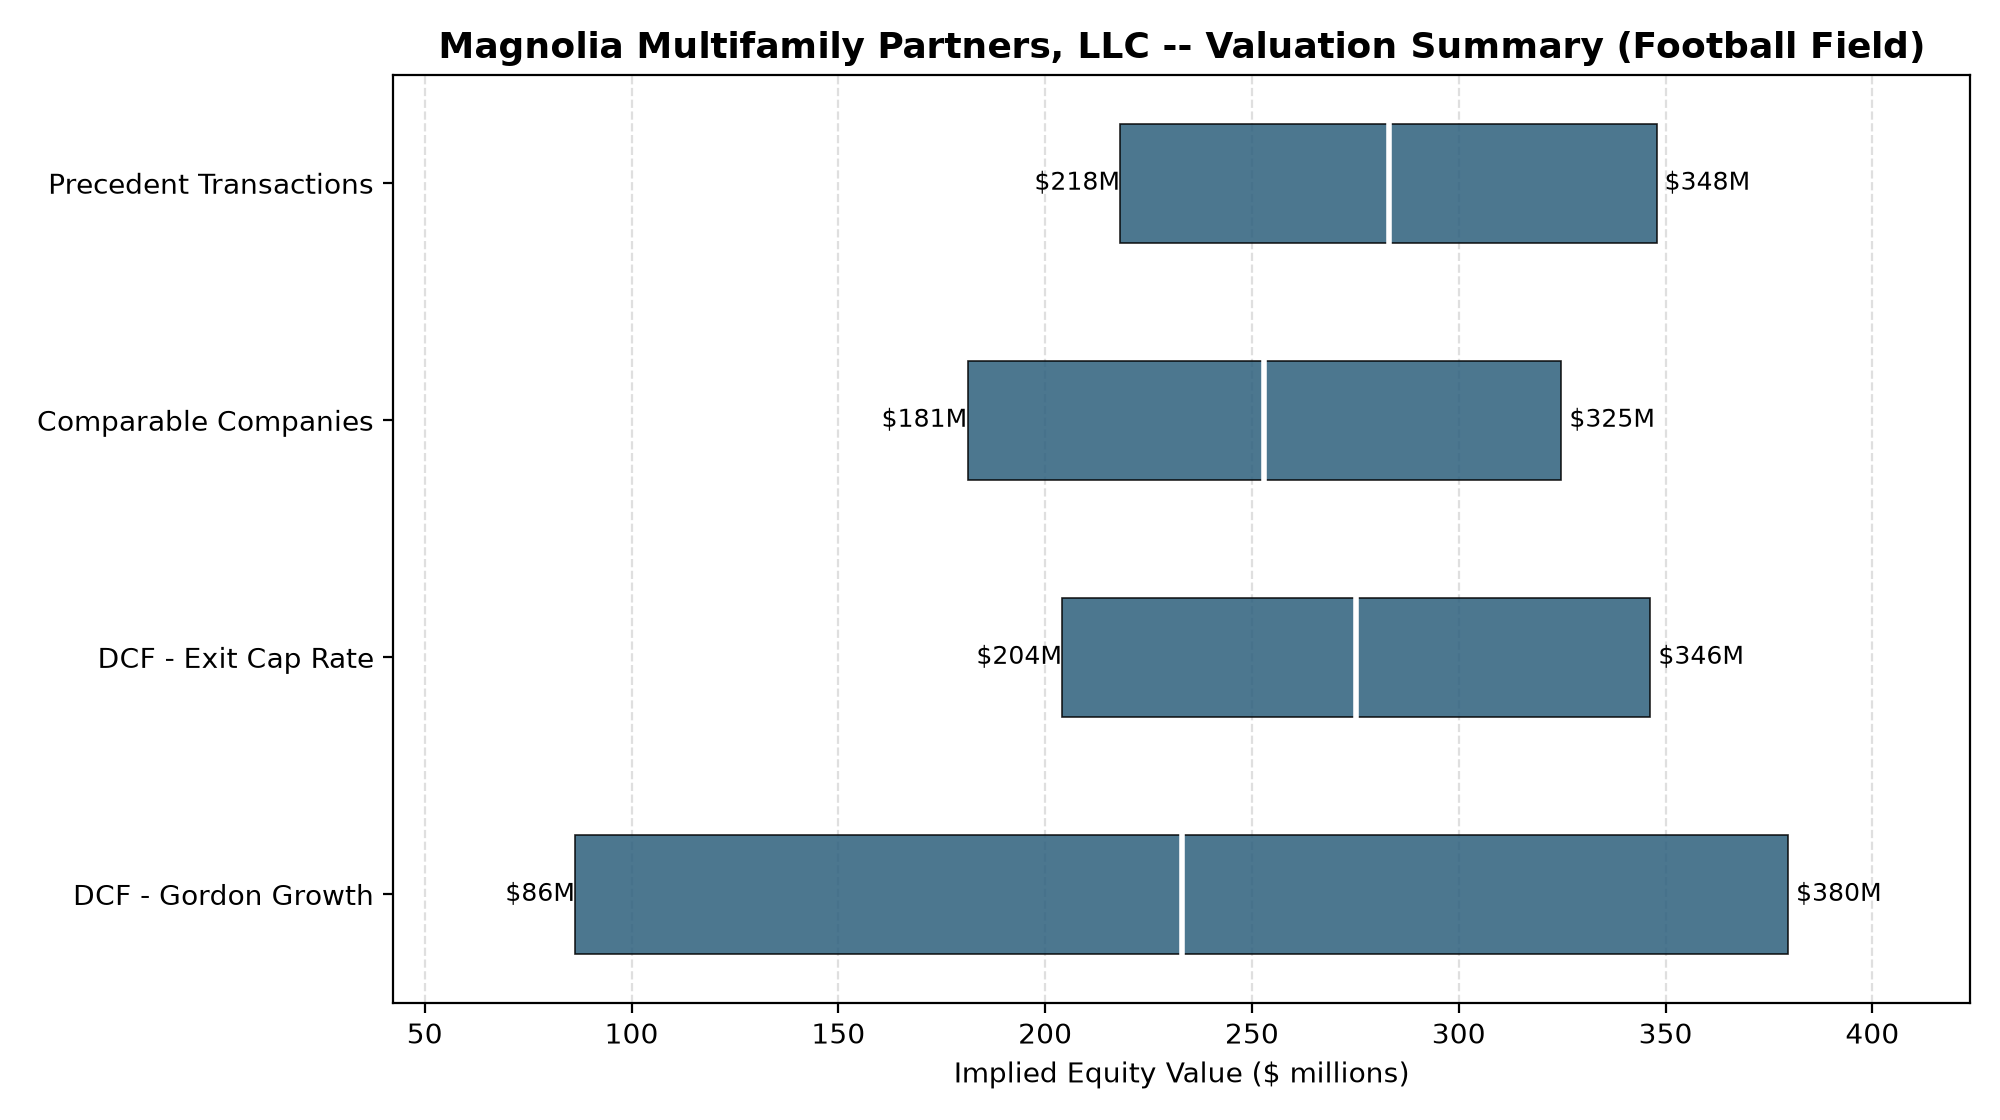

In [13]:
scenario.OUTPUT_DIR.mkdir(exist_ok=True)
chart_path = plot_football_field(ranges, scenario.COMPANY_NAME, str(scenario.OUTPUT_DIR / "football_field.png"))

from IPython.display import Image
Image(chart_path)

## 7. Buyer / Investor Screening

The buyer universe is scored on three qualitative criteria — geographic/submarket fit,
asset-class fit, and alignment with the buyer's stated investment thesis (all analyst
judgment calls, exactly as they would be in a real screen) — plus a mechanical capacity
score based on whether Magnolia's implied deal size actually falls inside each buyer's
typical check size range.

In [14]:
buyers = buyer_screening.load_buyers(str(scenario.DATA_DIR / "buyers.csv"))
scored_buyers = buyer_screening.score_buyers(buyers, implied_deal_size_millions=overall_mid / 1e6)
scored_buyers

,name,buyer_type,geographic_fit_score,asset_class_fit_score,thesis_alignment_score,capacity_score,weighted_score,leverage_appetite,description,notes
rank,,,,,,,,,,
1,Cascade Residential Trust,Strategic,5,5,5,5.00,5.00,Medium,Public multifamily REIT with an existing Sun B...,Owns assets in 3 of the 6 target submarkets al...
2,Ridgemont Living,Strategic,5,5,5,5.00,5.00,High,Private regional multifamily operator based in...,Direct competitor/adjacent operator in the sam...
3,Foundry Street Partners,Financial,4,4,5,5.00,4.60,Medium,Middle-market private equity real estate fund ...,Also a credible counterparty for a recap/growt...
4,Northgate Real Estate Capital,Financial,4,4,5,5.00,4.60,High,Value-add-focused private equity real estate f...,Fund has significant dry powder earmarked for ...
5,Bluepoint Residential Partners,Strategic,4,5,4,5.00,4.50,Medium,"Public multifamily REIT, national footprint, o...","Track record of similar-sized platform deals, ..."
6,Meridian Community Group,Strategic,4,4,4,5.00,4.30,Medium,Private Southeast multifamily platform backed ...,"Explicitly stated intent to add 2,500-4,000 un..."
7,Silverleaf Capital Partners,Financial,4,3,4,5.00,4.10,High,Opportunistic private equity real estate fund ...,Underwriting appetite for the lower-occupancy ...
8,Harborline Apartment REIT,Strategic,3,4,3,5.00,3.80,Low,"Public multifamily REIT, core strategy, lower ...",Would likely underwrite the Class B/B+ assets ...
9,Anchor Point Realty Advisors,Financial,3,4,3,5.00,3.80,Low,Institutional separate account manager investi...,Core-plus mandate is a stretch fit for the bel...


In [15]:
top_5 = buyer_screening.top_targets(scored_buyers, n=5)
top_5[["name", "buyer_type", "weighted_score", "description"]]

,name,buyer_type,weighted_score,description
rank,,,,
1,Cascade Residential Trust,Strategic,5.00,Public multifamily REIT with an existing Sun B...
2,Ridgemont Living,Strategic,5.00,Private regional multifamily operator based in...
3,Foundry Street Partners,Financial,4.60,Middle-market private equity real estate fund ...
4,Northgate Real Estate Capital,Financial,4.60,Value-add-focused private equity real estate f...
5,Bluepoint Residential Partners,Strategic,4.50,"Public multifamily REIT, national footprint, o..."


In [16]:
print(f"Recommended equity valuation range: ${overall_low/1e6:,.0f}M - ${overall_high/1e6:,.0f}M "
      f"(average midpoint ${overall_mid/1e6:,.0f}M)")

Recommended equity valuation range: $218M - $325M (average midpoint $261M)


## 8. Conclusion & Recommendation

Triangulating across the DCF, public comps, and precedent transactions, the four
methodologies cluster tightly around the recommended range printed above — a good sign
of a defensible range, since three independent methodologies (public trading multiples,
private M&A multiples, and a discounted cash flow) are corroborating each other rather
than diverging.

On the buyer side, the top of the ranked list is led by **Cascade Residential Trust**
and **Ridgemont Living** — both score a perfect fit on geography, asset class, and
thesis alignment, reflecting that they're already active, credible acquirers in exactly
this submarket mix. **Foundry Street Partners** and **Northgate Real Estate Capital**
round out a strong financial-buyer contingent, both well suited to the below-target-occupancy
assets that carry the portfolio's real lease-up upside.

**Recommendation:** run a dual-track process with parallel outreach to the top
strategic and financial buyers identified above, using the football field valuation
range to anchor management's price expectations heading into first-round bids. See
`output/deal_memorandum.md` for the client-ready summary of this work
(`python scripts/generate_outputs.py` regenerates both the memo and the chart from the
current assumptions).